### 1. Data Loading

In this section, we load the dataset and inspect its basic structure.

In [25]:
import pandas as pd

In [26]:
data = pd.read_csv('../data/raw/hour.csv')

In [27]:
data.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


_**Dataset Overview**_

We inspect the dataset dimensions and column names to understand its structure.

In [28]:
data.shape

(17379, 17)

In [29]:
data.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

_**Initial Dataset Overview**_

The dataset contains 17,379 hourly records and 17 columns. It includes time, weather, and rental information.

The target variable is `cnt`. The columns `casual` and `registered` will be excluded from the model features because their sum equals the target.

_**Feature Description**_

| Feature | Description |
|---|---|
| `instant` | Record index |
| `dteday` | Date of the record |
| `season` | Season of the year |
| `yr` | Year |
| `mnth` | Month |
| `hr` | Hour of the day |
| `holiday` | Indicates whether the day is a holiday |
| `weekday` | Day of the week |
| `workingday` | Indicates whether the day is a working day |
| `weathersit` | Weather conditions category |
| `temp` | Normalized temperature |
| `atemp` | Normalized feels-like temperature |
| `hum` | Normalized humidity |
| `windspeed` | Normalized wind speed |
| `casual` | Rentals by casual users |
| `registered` | Rentals by registered users |
| `cnt` | Total number of bike rentals (target variable) |

### 2. Data Quality Checks
In this section, we check the dataset for missing values and duplicate records to ensure data quality.

In [30]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [31]:
data.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [32]:
data.duplicated().sum()

np.int64(0)

_**Statistical Analysis**_
In this section, we examine the statistical properties of numerical features to understand their distributions and identify potential patterns.

In [33]:
data.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Observations

- All columns have 17,379 non-null values, which confirms that there are no missing values.
- The target variable `cnt` ranges from 1 to 977 with a mean of about 189.5 and a median of 142. The mean is noticeably higher than the median, which suggests a right-skewed distribution.
- The mean of `casual` (≈ 35.7) plus the mean of `registered` (≈ 153.8) equals the mean of `cnt` (≈ 189.5), which is consistent with `cnt = casual + registered`.
- `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday` and `weathersit` are categorical or binary codes, so their means and quartiles should not be interpreted as ordinary numeric statistics. Only their ranges are informative (for example, `hr` from 0 to 23 and `weathersit` from 1 to 4).
- `temp`, `atemp`, `hum` and `windspeed` are normalized, so their values are not in degrees, percent or m/s.
- `hum` and `windspeed` have a minimum value of 0. These values need a closer look in later sections, because zero humidity is physically implausible.
- The mean of `yr` (≈ 0.50) shows that the records are split almost evenly between the two years.
- The mean of `holiday` (≈ 0.029) shows that only about 3% of records fall on holidays.

### 3. Target Variable Distribution
In this section, we visualize the distribution of the target variable to understand hourly bike rental demand.

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

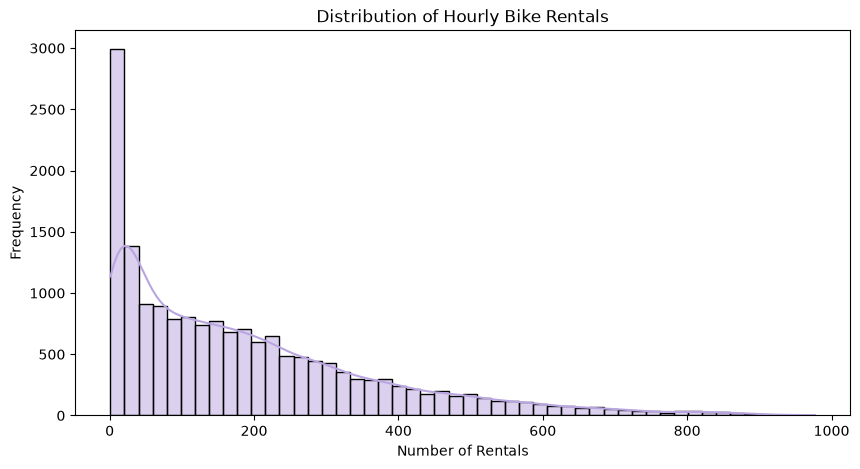

In [35]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='cnt', bins=50, kde=True, color="#B9A5E0")

plt.title('Distribution of Hourly Bike Rentals')
plt.xlabel('Number of Rentals')
plt.ylabel('Frequency')

plt.show()

The target variable cnt has a right-skewed distribution. Most hourly rental counts are relatively low, while high rental counts occur less frequently. The mean (189.46) is higher than the median (142), which is consistent with the observed distribution.

### 4. Hourly Rental Demand
In this section, we analyze how hourly bike rental demand changes throughout the day by examining the average number of rentals for each hour.

In [36]:
hourly_demand = data.groupby('hr')['cnt'].mean().reset_index()

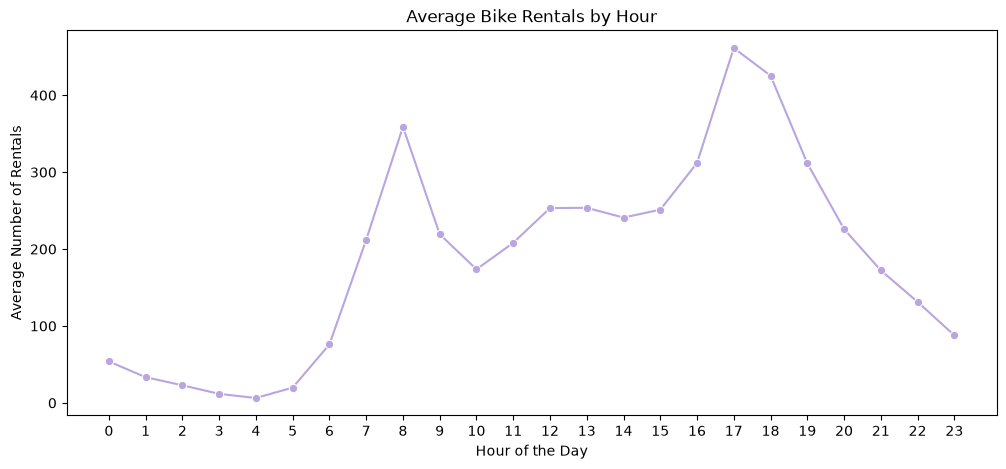

In [37]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=hourly_demand, x='hr', y='cnt', marker='o', color="#B9A5E0")

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(24))

plt.show()

The average number of rentals changes strongly during the day. Demand is lowest in the early morning, with a minimum at 4:00 (≈ 6 rentals on average), and starts to grow after 5:00.

There are two clear peaks. The morning peak occurs at 8:00 (≈ 360 rentals), followed by a drop to ≈ 175 at 10:00. Between the peaks, demand stays at a moderate level of ≈ 240–255 rentals. The evening peak is the highest: it occurs at 17:00 (≈ 460 rentals), with demand remaining high at 18:00 (≈ 425). After that, demand decreases steadily through the evening.

This pattern suggests that `hr` is an important feature for predicting demand. The graph shows an association between the hour and the average demand, not a cause. These averages combine all days, so the pattern may differ between working and non-working days.

### 5. Weekday Rental Demand

In this section, we analyze how average bike rental demand varies across different days of the week.

_**Average Rentals by Day of the Week**_

We calculate the average number of bike rentals for each day of the week and visualize the results to identify differences in rental demand.

In [38]:
weekday_demand = data.groupby('weekday')['cnt'].mean().reset_index()

In [39]:
weekday_names = {
    0: 'Sunday',
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday'
}

In [40]:
weekday_demand['weekday_name'] = weekday_demand['weekday'].map(weekday_names)

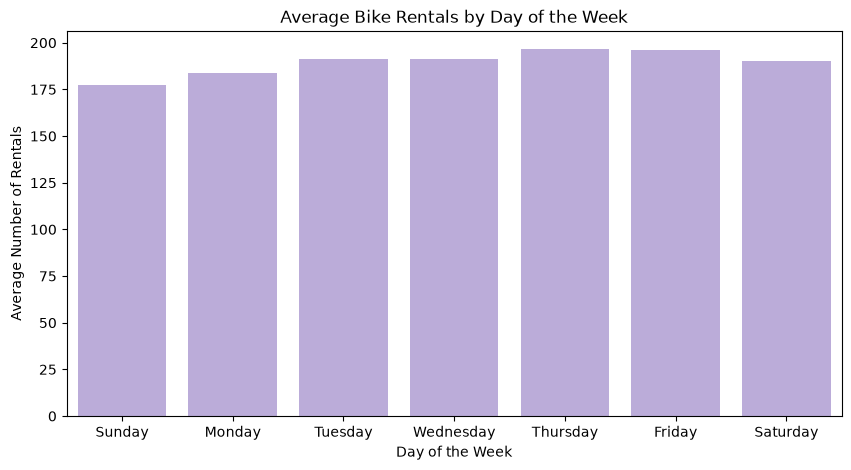

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(data=weekday_demand, x='weekday_name', y='cnt', color="#B9A5E0")

plt.title('Average Bike Rentals by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Number of Rentals')

plt.show()

The average hourly rental demand remains relatively stable across the week. Thursday and Friday show the highest average rental counts, while Sunday has the lowest. The differences between days are relatively small compared to the hourly variations observed earlier.

### 6. Seasonal Rental Demand

We calculate the average number of bike rentals for each season and visualize the results to identify seasonal patterns in rental demand.

In [42]:
seasonal_demand = data.groupby('season')['cnt'].mean().reset_index()

In [43]:
season_names = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}

seasonal_demand['season_name'] = seasonal_demand['season'].map(season_names)

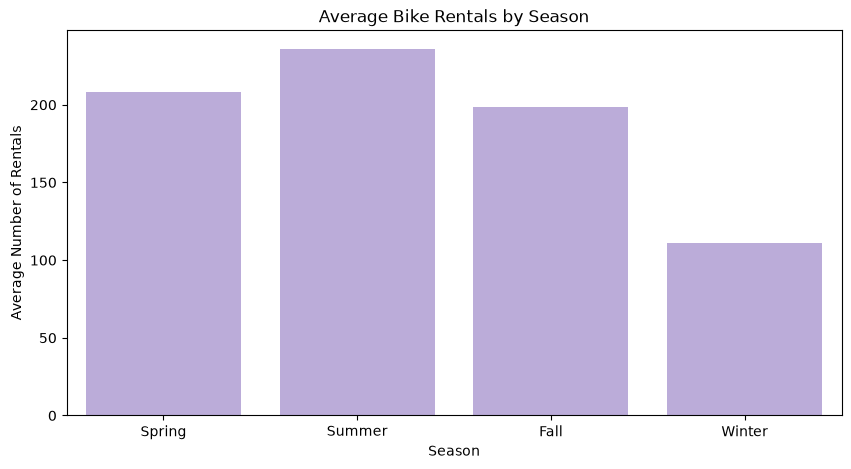

In [44]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=seasonal_demand,
    x='season_name',
    y='cnt',
    order=['Spring', 'Summer', 'Fall', 'Winter'], color="#B9A5E0"
)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Number of Rentals')

plt.show()

- Average hourly rentals are highest in summer (about 236) and lowest in winter (about 110); spring (about 208) and fall (about 199) are in between.
- Seasonal differences are more noticeable than differences between weekdays.
- This is consistent with the monthly pattern: demand is lowest in January-February and highest from June to September.

### 7. Average Rentals by Weather Condition

We calculate the average number of bike rentals for each weather condition and visualize the results to identify patterns in rental demand.

In [45]:
weather_demand = data.groupby('weathersit').agg(
    avg_rentals=('cnt', 'mean'),
    records=('cnt', 'count')
).reset_index()

In [46]:
weather_names = {
    1: 'Clear',
    2: 'Mist / Cloudy',
    3: 'Light Rain / Snow',
    4: 'Heavy Rain / Snow'
}

weather_demand['weather_name'] = weather_demand['weathersit'].map(weather_names)

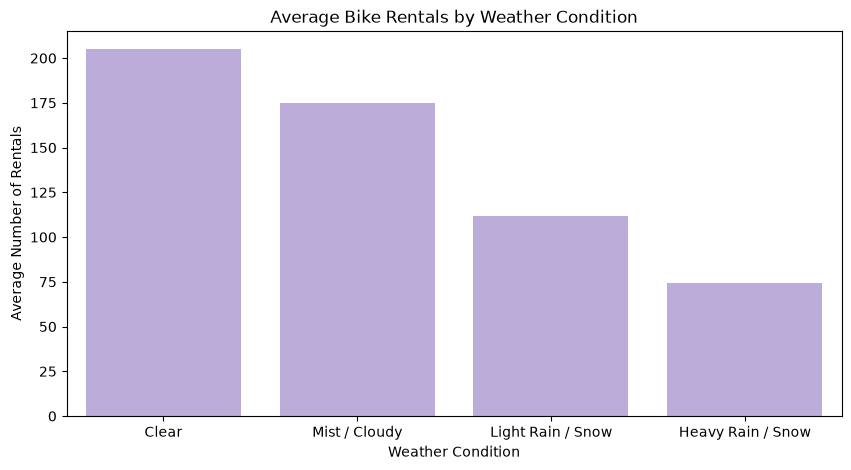

In [47]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weather_demand,
    x='weather_name',
    y='avg_rentals',
    color="#B9A5E0",
    order=[
        'Clear',
        'Mist / Cloudy',
        'Light Rain / Snow',
        'Heavy Rain / Snow'
    ]
)

plt.title('Average Bike Rentals by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Number of Rentals')

plt.show()


In [48]:
print(weather_demand)

   weathersit  avg_rentals  records       weather_name
0           1   204.869272    11413              Clear
1           2   175.165493     4544      Mist / Cloudy
2           3   111.579281     1419  Light Rain / Snow
3           4    74.333333        3  Heavy Rain / Snow


The analysis shows a decrease in average bike rental demand as weather conditions become less favorable across the first three weather categories. Clear weather has the highest average rental count, followed by misty or cloudy conditions and light rain or snow.

However, the Heavy Rain / Snow category contains only 3 observations. Therefore, its average rental count may not be representative, and no reliable conclusions can be drawn for this category.

### 8. Temperature Analysis

In this section, we study how temperature is related to the number of hourly
bike rentals (`cnt`).

The `temp` column is normalized using min-max scaling. According to the dataset
documentation, the original range was from -8 °C to +39 °C, so we convert
temperature back with `temp * 47 - 8`. The converted values are approximate,
but they are much easier to interpret than normalized numbers.

We will:
1. Look at the distribution of temperature.
2. Plot temperature against rentals using a scatter plot.
3. Calculate average rentals and the number of records for each temperature range.
4. Calculate correlation coefficients between temperature and rentals.

**_8.1 Distribution of Temperature_**
We first convert temperature to degrees Celsius and look at how the values are distributed across all records.

In [49]:
temp_data = data[['temp', 'cnt']].copy()
temp_data['temp_celsius'] = temp_data['temp'] * 47 - 8

print(temp_data['temp_celsius'].describe())

count    17379.000000
mean        15.358397
std          9.050138
min         -7.060000
25%          7.980000
50%         15.500000
75%         23.020000
max         39.000000
Name: temp_celsius, dtype: float64


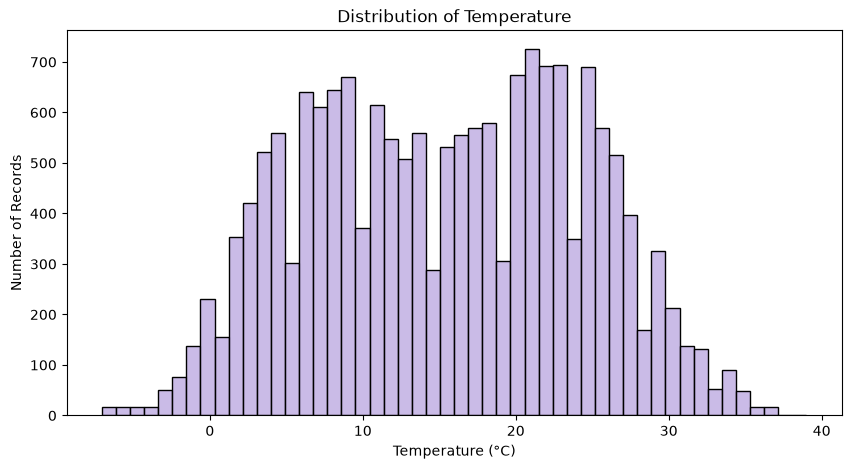

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=temp_data,
    x='temp_celsius',
    bins=50,
    color="#B9A5E0"
)

plt.title('Distribution of Temperature')
plt.xlabel('Temperature (°C)')
plt.ylabel('Number of Records')

plt.show()

In [51]:
print(data['temp'].nunique())

50


- Temperature ranges from about -7 °C to 39 °C, with most records between roughly 3 °C and 28 °C.
- The distribution is broad and roughly symmetric, consistent with the mean (15.36 °C) and median (15.5 °C) being almost equal. There are two wide plateaus (around 5-12 °C and 20-26 °C), but no clearly separated groups.
- Very cold (below 0 °C) and very hot (above 33 °C) hours are rare, so averages in these ranges will rely on fewer records and should be interpreted with caution.
- The `temp` column has only 50 distinct values (spacing of about 0.94 °C). With 30 bins, some bins captured two values and others one, which created an artificial zigzag; with 50 bins the pattern is much smoother.

**_8.2 Temperature vs. Rentals_**

We plot temperature against hourly rentals using a scatter plot to see how demand changes as it gets warmer. Each point is one hour; transparency (`alpha=0.2`) helps to show where many points overlap.

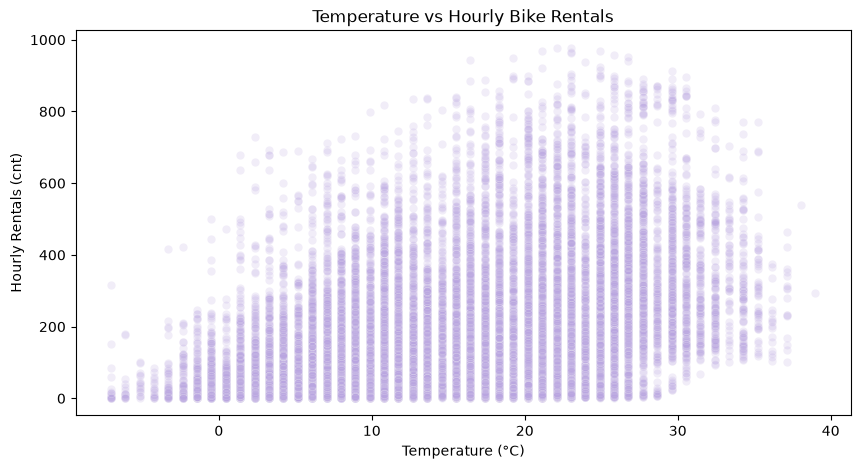

In [52]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=temp_data,
    x='temp_celsius',
    y='cnt',
    alpha=0.2,
    color="#B9A5E0"
)

plt.title('Temperature vs Hourly Bike Rentals')
plt.xlabel('Temperature (°C)')
plt.ylabel('Hourly Rentals (cnt)')

plt.show()

- Hourly rentals tend to increase as temperature rises: the upper boundary of the point cloud grows from roughly 200-300 rentals per hour below 0 °C to nearly 1000 at around 20-27 °C.
- The upper boundary appears to decline at higher temperatures (above roughly 30 °C). However, there are fewer records in this range, so this should be confirmed with average values and record counts.
- At any given temperature, rentals vary widely, from almost 0 to several hundred. Temperature alone explains only part of the variation in demand; other factors such as hour of day are likely to matter.
- The points form vertical columns because `temp` has only 50 distinct values.
- Observations at the extreme ends (below about -3 °C and above about 35 °C) are sparse, so conclusions about these ranges are not reliable.

**_8.3 Average Rentals by Temperature Range_**

To see the trend more clearly than on the scatter plot, we split temperature into 5 °C ranges and calculate the average number of rentals and the number of records in each range. The number of records shows how reliable each average is.

In [54]:
bins = range(-10, 45, 5)

temp_data['temp_range'] = pd.cut(
    temp_data['temp_celsius'],
    bins=bins,
    include_lowest=True
)

temp_summary = (
    temp_data
    .groupby('temp_range', observed=True)['cnt']
    .agg(avg_rentals='mean', records='count')
    .reset_index()
)

print(temp_summary)

        temp_range  avg_rentals  records
0  (-10.001, -5.0]    39.877551       49
1      (-5.0, 0.0]    58.832031      512
2       (0.0, 5.0]    78.565390     2011
3      (5.0, 10.0]   134.530392     3241
4     (10.0, 15.0]   169.066773     2516
5     (15.0, 20.0]   206.166929     2540
6     (20.0, 25.0]   224.759739     3825
7     (25.0, 30.0]   317.066296     1976
8     (30.0, 35.0]   330.774400      625
9     (35.0, 40.0]   292.809524       84


- Average hourly rentals increase with temperature across most of the range: from about 40 rentals below -5 °C to about 331 at 30-35 °C, roughly an eight-fold difference.
- The increase is not uniform. The largest jumps occur between 0-5 °C and 5-10 °C, and between 20-25 °C and 25-30 °C.
- Demand appears to level off at 25-35 °C (about 317 and 331 rentals). The average is lower at 35-40 °C (about 293), but this range contains only 84 records, so it cannot be treated as reliable evidence of a decline in demand at extreme heat.
- The coldest range (below -5 °C, 49 records) and the hottest range (35-40 °C, 84 records) contain very few observations, so their averages should be interpreted with caution.

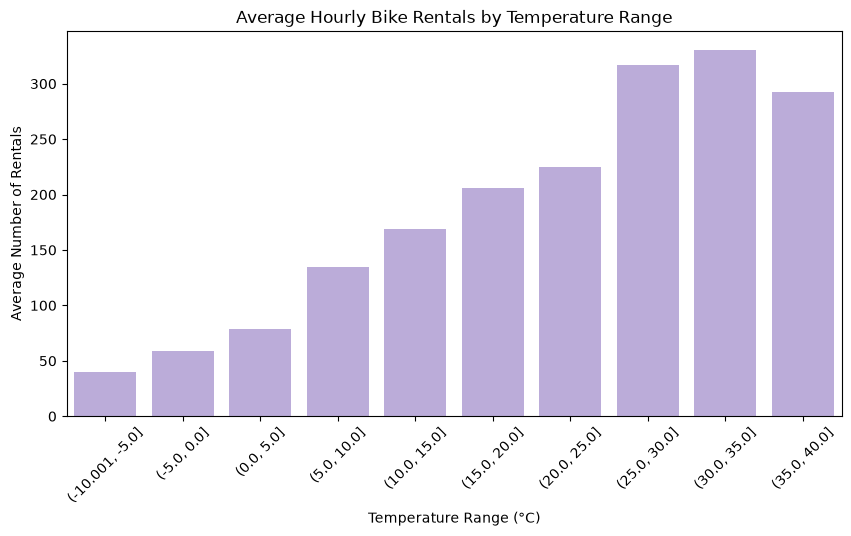

In [55]:
temp_summary['temp_range'] = temp_summary['temp_range'].astype(str)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=temp_summary,
    x='temp_range',
    y='avg_rentals',
    color="#B9A5E0"
)

plt.title('Average Hourly Bike Rentals by Temperature Range')
plt.xlabel('Temperature Range (°C)')
plt.ylabel('Average Number of Rentals')
plt.xticks(rotation=45)

plt.show()

а

_**8.4 Correlation Between Temperature and Rentals**_

The scatter plot and the bar chart show that average hourly rentals tend to
increase with temperature. Now we measure the strength of this association with
a single number.

We calculate two correlation coefficients:
- **Pearson** measures the strength of a *linear* relationship.
- **Spearman** measures the strength of a *monotonic* relationship (rentals
  generally rise as temperature rises, not necessarily along a straight line).

Correlation coefficients summarize the association but do not replace the plots:
they do not show the shape of the relationship, such as the leveling off at
high temperatures. They also do not prove causation.

In [31]:
pearson_corr = temp_data['temp'].corr(temp_data['cnt'], method='pearson')
spearman_corr = temp_data['temp'].corr(temp_data['cnt'], method='spearman')

print(f'Pearson correlation:  {pearson_corr:.3f}')
print(f'Spearman correlation: {spearman_corr:.3f}')

Pearson correlation:  0.405
Spearman correlation: 0.423


- Both coefficients are positive and moderate: Pearson = 0.405 and Spearman = 0.423, so rentals tend to increase with temperature, but the association is far from perfect.
- The squared Pearson coefficient (about 0.16) means that a linear relationship with temperature describes only a small share of the variation in hourly rentals, which agrees with the wide spread of points seen in the scatter plot.
- Spearman (0.423) is slightly higher than Pearson (0.405), which is consistent with a relationship that is monotonic but not perfectly linear. The plots show that the growth is step-like and levels off at high temperatures, which a single correlation number cannot capture.
- Correlation shows association, not causation. Temperature is also related to season and time of day.

### 9. Feature Relationships

In this section, we study how the continuous weather features are related to
the number of hourly rentals (`cnt`) and to each other.

We use `temp`, `atemp`, `hum` and `windspeed`. The columns `casual` and
`registered` are not used, because they sum up to `cnt` and would cause target
leakage. Features such as `hr`, `season` or `weekday` are category codes, and
their relationship with `cnt` is not linear (for example, demand has two peaks
during the day), so a Pearson correlation would be misleading for them.

In [32]:
features_for_corr = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']

corr_matrix = data[features_for_corr].corr()

print(corr_matrix.round(3))

            temp  atemp    hum  windspeed    cnt
temp       1.000  0.988 -0.070     -0.023  0.405
atemp      0.988  1.000 -0.052     -0.062  0.401
hum       -0.070 -0.052  1.000     -0.290 -0.323
windspeed -0.023 -0.062 -0.290      1.000  0.093
cnt        0.405  0.401 -0.323      0.093  1.000


- `temp` (0.405) and `atemp` (0.401) have a moderate positive correlation with `cnt`; `hum` has a moderate negative correlation (-0.323); `windspeed` has a very weak positive correlation (0.093).
- `temp` and `atemp` are almost perfectly correlated (0.988), so they carry nearly the same information. Whether to keep both will be decided during modeling, because redundant features can affect linear models more than tree-based models.
- `hum` and `windspeed` are weakly related to each other (-0.290), and both are almost uncorrelated with `temp`, so they are not linearly redundant with temperature.
- Pearson correlation measures only linear association. A weak correlation does not mean that a feature is useless.
- Zero values in `hum` and `windspeed` are included in these calculations and will be examined separately.

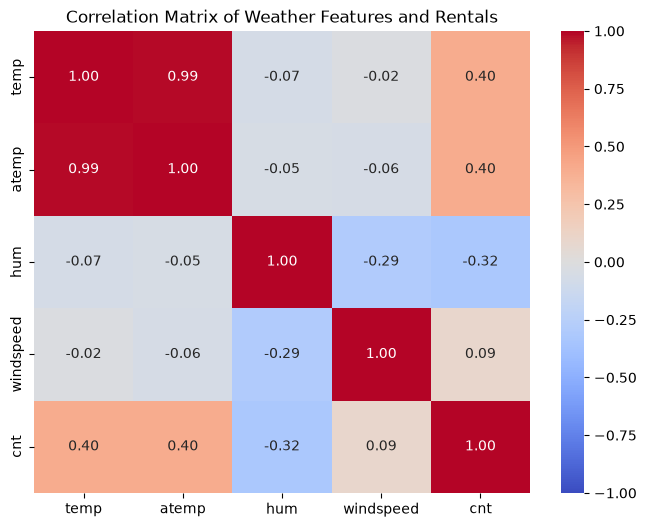

In [33]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Weather Features and Rentals')

plt.show()

- The heatmap confirms the correlation table. The strongest off-diagonal relationship is between `temp` and `atemp` (0.99), so these two features are almost redundant.
- Compared with `cnt`, `temp` and `atemp` show a moderate positive correlation (about 0.40), `hum` a moderate negative one (-0.32), and `windspeed` a very weak one (0.09).
- `hum` and `windspeed` are weakly negatively correlated with each other (-0.29), and both are almost uncorrelated with temperature.
- The heatmap shows only linear association. It does not capture non-linear patterns and does not prove causation.

**_Temperature vs. Feels-Like Temperature_**

The correlation between `temp` and `atemp` is 0.988. To check what this looks like in the data, we plot the two features against each other.

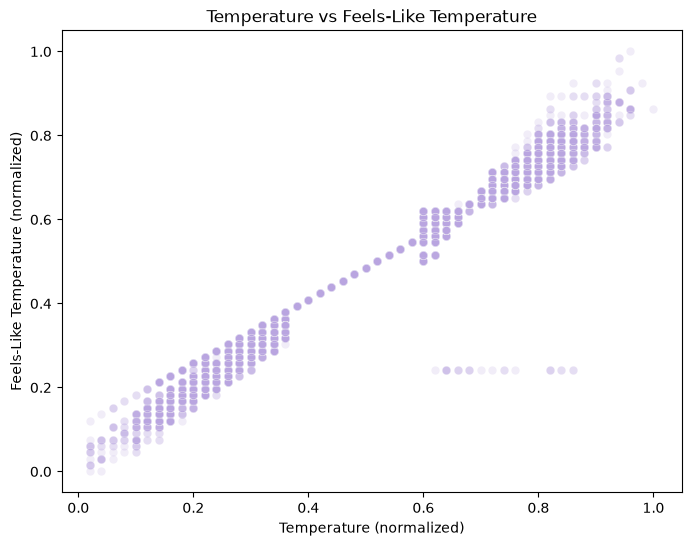

In [56]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x='temp',
    y='atemp',
    alpha=0.2,
    color="#B9A5E0"
)

plt.title('Temperature vs Feels-Like Temperature')
plt.xlabel('Temperature (normalized)')
plt.ylabel('Feels-Like Temperature (normalized)')

plt.show()

In [35]:
suspicious = data[(data['temp'] > 0.6) & (data['atemp'] < 0.3)]

print(len(suspicious))
print(suspicious[['dteday', 'hr', 'temp', 'atemp']].head(10))
print(suspicious['dteday'].min(), suspicious['dteday'].max())

24
           dteday  hr  temp   atemp
14131  2012-08-17   0  0.68  0.2424
14132  2012-08-17   1  0.66  0.2424
14133  2012-08-17   2  0.66  0.2424
14134  2012-08-17   3  0.64  0.2424
14135  2012-08-17   4  0.64  0.2424
14136  2012-08-17   5  0.64  0.2424
14137  2012-08-17   6  0.62  0.2424
14138  2012-08-17   7  0.64  0.2424
14139  2012-08-17   8  0.68  0.2424
14140  2012-08-17   9  0.70  0.2424
2012-08-17 2012-08-17


In [36]:
print(data[data['dteday'] == '2012-08-17']['atemp'].describe())

count    2.400000e+01
mean     2.424000e-01
std      2.835254e-17
min      2.424000e-01
25%      2.424000e-01
50%      2.424000e-01
75%      2.424000e-01
max      2.424000e-01
Name: atemp, dtype: float64


- Most points lie along a narrow diagonal band, which confirms that `temp` and `atemp` are almost redundant (correlation 0.99).
- A horizontal row of points appears at `atemp` ≈ 0.24 while `temp` ranges from about 0.62 to 0.86. This is not physically plausible and suggests a data recording problem.
- Checking these points showed 24 records (about 0.14% of the data), which are all the hourly records of a single date, 2012-08-17. On this date `atemp` is constant at 0.2424 for all 24 hours, while `temp` changes during the day. The cause is unknown.
- Because the number of affected records is very small, the overall correlation (0.988) hides the problem. This shows why correlation should be checked together with plots.
- We do not modify or remove these records now; the decision will be made during data preparation.

**_Humidity vs. Hourly Rentals_**

We plot humidity against hourly rentals to see how demand changes with humidity and to check the values of `hum` for anomalies.

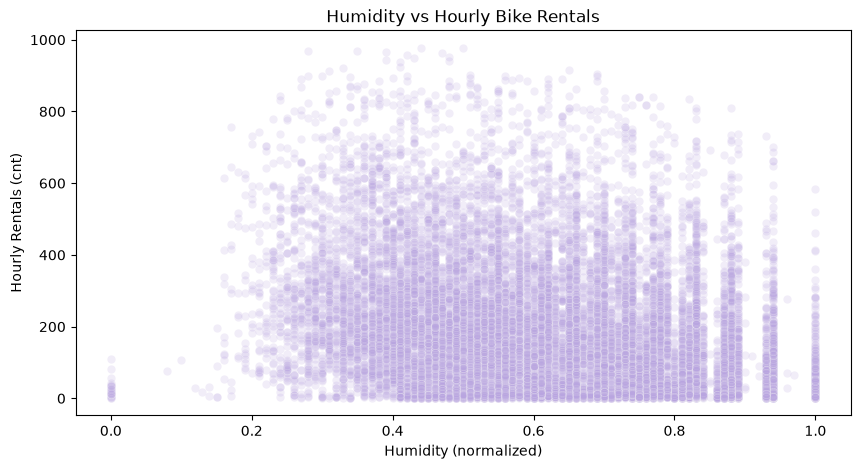

In [57]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=data,
    x='hum',
    y='cnt',
    alpha=0.2,
    color="#B9A5E0"

)

plt.title('Humidity vs Hourly Bike Rentals')
plt.xlabel('Humidity (normalized)')
plt.ylabel('Hourly Rentals (cnt)')

plt.show()

In [38]:
zero_hum = data[data['hum'] == 0]

print(len(zero_hum))
print(zero_hum['dteday'].value_counts())
print(zero_hum[['dteday', 'hr', 'hum', 'cnt']].head(10))

22
dteday
2011-03-10    22
Name: count, dtype: int64
          dteday  hr  hum  cnt
1551  2011-03-10   0  0.0    3
1552  2011-03-10   1  0.0    2
1553  2011-03-10   2  0.0    1
1554  2011-03-10   5  0.0    3
1555  2011-03-10   6  0.0   12
1556  2011-03-10   7  0.0   37
1557  2011-03-10   8  0.0   44
1558  2011-03-10   9  0.0   24
1559  2011-03-10  10  0.0   17
1560  2011-03-10  11  0.0   11


- The upper boundary of the point cloud first rises (up to about 0.3-0.5 humidity), then declines at high humidity: it is roughly 700-800 rentals at 0.8-0.9 and about 580 at 1.0. This agrees with the moderate negative correlation (-0.32), but the relationship is not a simple linear decrease.
- At any given humidity, rentals vary widely, so humidity alone explains only part of the variation in demand.
- A small group of points appears at `hum` = 0, separated from the main data. Zero humidity is not physically plausible. Checking these points showed 22 records (about 0.13% of the data), all from a single date, 2011-03-10. The cause is unknown.
- Observations with humidity below about 0.2 are sparse, so the lower upper boundary there should not be over-interpreted.
- We do not modify or remove these records now; the decision will be made during data preparation.
- This plot shows an association, not causation. High humidity often goes together with rainy or cloudy weather.

**_Wind Speed vs. Hourly Rentals_**

We plot wind speed against hourly rentals and check the many zero values of `windspeed`.

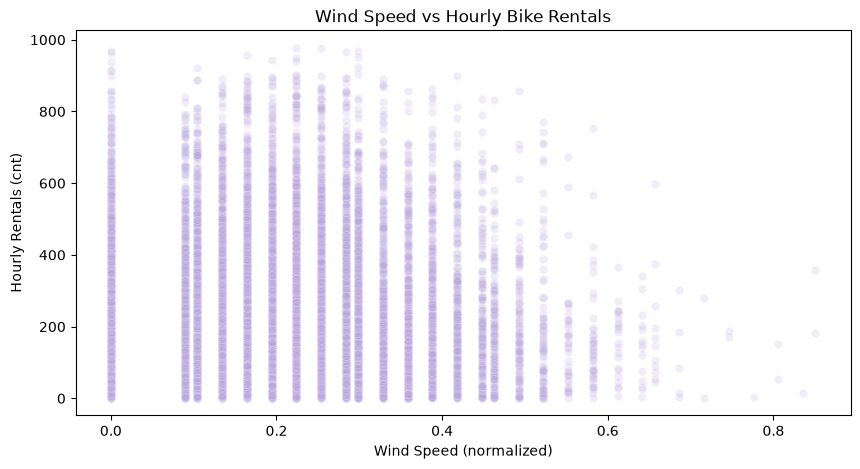

In [58]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=data,
    x='windspeed',
    y='cnt',
    alpha=0.2,
    color="#B9A5E0"
)

plt.title('Wind Speed vs Hourly Bike Rentals')
plt.xlabel('Wind Speed (normalized)')
plt.ylabel('Hourly Rentals (cnt)')

plt.show()

In [40]:
zero_wind = data[data['windspeed'] == 0]
nonzero_wind = data[data['windspeed'] > 0]

print(len(zero_wind))
print(zero_wind['dteday'].nunique())
print(nonzero_wind['windspeed'].min())
print(zero_wind['cnt'].mean(), nonzero_wind['cnt'].mean())

2180
521
0.0896
160.6435779816514 193.59668399236793


- The weak correlation between `windspeed` and `cnt` (0.09) hides a more complex pattern. The upper boundary of the point cloud is roughly flat up to about 0.3, then declines at higher wind speeds (below about 400 rentals above 0.65), but there are few records at high wind speeds, so this should be interpreted with caution.
- `windspeed` has 2,180 records (about 12.5% of the data) equal to 0, spread across 521 different dates. The smallest positive value is 0.0896, so there is a gap between 0 and the rest of the values. Zeros may mean wind below a measurement threshold or a missing measurement rather than calm air; the cause is unknown.
- Average hourly rentals are lower when `windspeed` is 0 (about 161) than when it is positive (about 194). This difference may partly explain why the correlation is slightly positive, but we have not checked why demand is lower.
- At any wind speed, rentals vary widely.
- We do not modify these records now; the decision will be made during data preparation.

### Summary of Feature Relationships

- `temp` and `atemp` have a moderate positive correlation with `cnt` (about 0.40), `hum` a moderate negative one (-0.32), and `windspeed` a very weak one (0.09). At any value of these features, hourly rentals vary widely, so no single weather feature explains demand on its own.
- `temp` and `atemp` are almost redundant (correlation 0.99). Whether to keep both will be decided during modeling.
- Plots revealed data issues that summary statistics did not: `atemp` is constant (0.2424) for all 24 hours of 2012-08-17; `hum` equals 0 for 22 records on 2011-03-10; and `windspeed` equals 0 in 2,180 records (about 12.5%) with a gap up to the next value (0.0896), which may indicate values below a measurement threshold or missing measurements.
- These records are not modified at this stage. How to handle them will be decided during data preparation.
- Correlation shows only linear association, and none of these results prove causation. The usefulness of each feature will be checked during modeling.

### 10. Yearly Rental Demand

In this section, we compare average hourly rentals between the two years in
the dataset. In the `yr` column, `0` stands for 2011 and `1` stands for 2012.

This matters for modeling: the data are ordered in time, so if demand differs
between years, it affects how we should split the data into training,
validation and test sets.

   yr  avg_rentals  records year_name
0   0   143.794448     8645      2011
1   1   234.666361     8734      2012


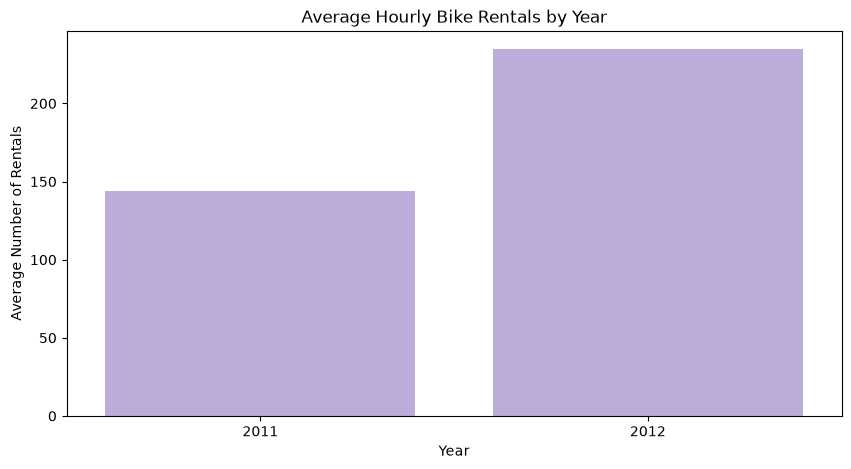

In [59]:
yearly_demand = (
    data
    .groupby('yr')['cnt']
    .agg(avg_rentals='mean', records='count')
    .reset_index()
)

yearly_demand['year_name'] = yearly_demand['yr'].map({0: '2011', 1: '2012'})

print(yearly_demand)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_demand,
    x='year_name',
    y='avg_rentals',
    color="#B9A5E0"
)

plt.title('Average Hourly Bike Rentals by Year')
plt.xlabel('Year')
plt.ylabel('Average Number of Rentals')

plt.show()

- Average hourly rentals are substantially higher in 2012 (about 235) than in 2011 (about 144), a difference of roughly 91 rentals, or about 63%.
- Both years contain a similar number of records (8,645 and 8,734). Both are slightly below the number of hours in the year (8,760 and 8,784), so some hours are absent from the data; the reason is unknown.
- The cause of the difference between years cannot be determined from this analysis.
- This is important for modeling: demand level shifts over time, so the way the data are split into training, validation and test sets will affect the results and must be chosen carefully.
- This analysis shows association, not causation.

### 11. Working Day vs. Non-Working Day Demand

In this section, we compare average hourly rentals on working days and
non-working days. In the `workingday` column, `1` means a day that is neither
a weekend nor a holiday, and `0` means a weekend or a holiday.

We also check the number of records in each group, so we know how reliable the
averages are.

   workingday  avg_rentals  records           day_type
0           0   181.405332     5514  Weekend / Holiday
1           1   193.207754    11865        Working Day


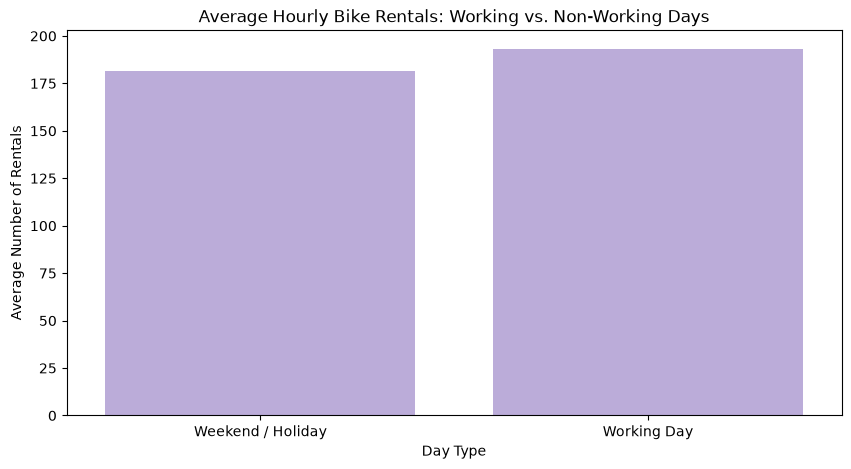

In [60]:
workingday_demand = (
    data
    .groupby('workingday')['cnt']
    .agg(avg_rentals='mean', records='count')
    .reset_index()
)

workingday_demand['day_type'] = workingday_demand['workingday'].map({
    0: 'Weekend / Holiday',
    1: 'Working Day'
})

print(workingday_demand)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=workingday_demand,
    x='day_type',
    y='avg_rentals',
    color="#B9A5E0"
)

plt.title('Average Hourly Bike Rentals: Working vs. Non-Working Days')
plt.xlabel('Day Type')
plt.ylabel('Average Number of Rentals')

plt.show()

- Average hourly rentals are slightly higher on working days (about 193) than on weekends and holidays (about 181), a difference of roughly 12 rentals, or about 6.5%.
- Both groups contain many records (11,865 working-day records and 5,514 non-working-day records), so the averages are reasonably reliable.
- The difference in daily averages is small, but averages over all 24 hours can hide differences in the daily pattern, for example in the timing of demand peaks. This is checked in the next step.
- The group `workingday = 0` combines weekends and holidays.

_**Hourly Demand: Working vs. Non-Working Days**_

The average daily difference between working and non-working days is small, but
averages over all 24 hours can hide differences in the daily pattern. Here we
compare the average number of rentals for each hour of the day separately for
the two day types.

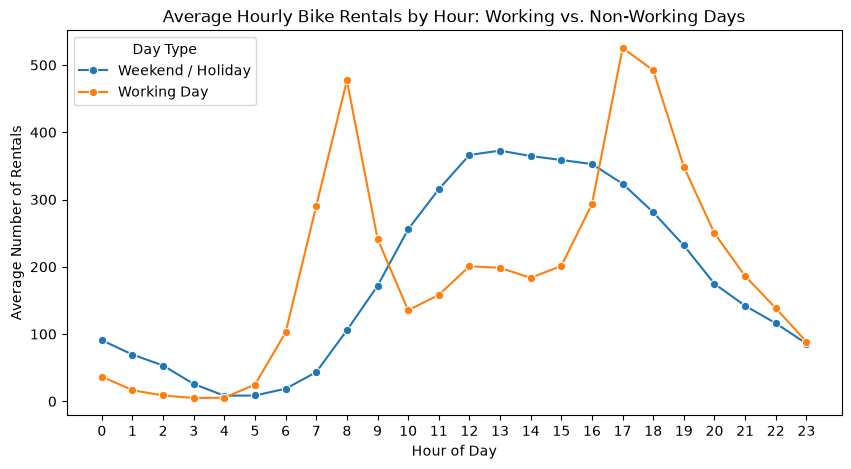

In [43]:
hourly_by_daytype = (
    data
    .groupby(['hr', 'workingday'])['cnt']
    .mean()
    .reset_index(name='avg_rentals')
)

hourly_by_daytype['day_type'] = hourly_by_daytype['workingday'].map({
    0: 'Weekend / Holiday',
    1: 'Working Day'
})

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_by_daytype,
    x='hr',
    y='avg_rentals',
    hue='day_type',
    marker='o'
)

plt.title('Average Hourly Bike Rentals by Hour: Working vs. Non-Working Days')
plt.xlabel('Hour of Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(0, 24))
plt.legend(title='Day Type')

plt.show()

- On working days, demand has two sharp peaks: one around 8:00 (about 480 rentals) and one around 17:00 (about 525 rentals, with 18:00 only slightly lower). Between the peaks, demand stays at roughly 135-200 rentals.
- On weekends and holidays, there is a single broad peak around 12:00-14:00 (about 370 rentals), with no sharp morning or evening peaks.
- The two curves cross twice (between 9:00 and 10:00 and between 16:00 and 17:00). Working days are higher during the rush hours; non-working days are higher in the middle of the day.
- Demand in the early morning hours (0:00-2:00) is higher on non-working days, and the curves almost coincide at 23:00.
- This explains why the daily averages are similar: high rush-hour peaks on working days and the high midday demand on non-working days roughly offset each other.
- The non-working group has fewer records (about 230 per hour versus about 490), so its curve is based on less data, although its shape is smooth.
- The effect of `hr` depends on `workingday`, so the combination of these features may matter for modeling. The two-peak pattern is consistent with commuting, but this analysis shows association, not causation.

### 12. Holiday Demand

In this section, we compare average hourly rentals on holidays and on regular
days. In the `holiday` column, `1` means a holiday and `0` means a regular day.

Holidays are rare, so we also count the number of records and the number of
distinct dates in each group. The hourly records of one day are similar to each
other, so the number of distinct days matters more than the number of records
when judging how reliable the averages are.

   holiday  avg_rentals  records  days     day_type
0        0    190.42858    16879   710  Regular Day
1        1    156.87000      500    21      Holiday


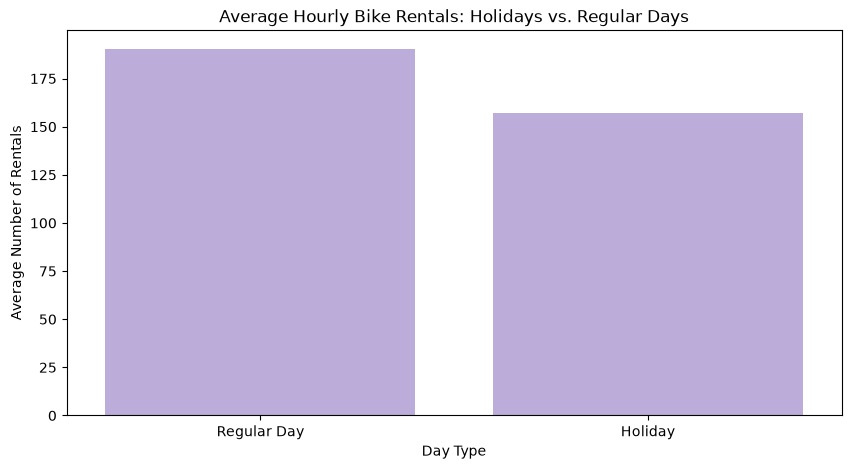

In [45]:
holiday_demand = (
    data
    .groupby('holiday')
    .agg(
        avg_rentals=('cnt', 'mean'),
        records=('cnt', 'count'),
        days=('dteday', 'nunique')
    )
    .reset_index()
)

holiday_demand['day_type'] = holiday_demand['holiday'].map({
    0: 'Regular Day',
    1: 'Holiday'
})

print(holiday_demand)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=holiday_demand,
    x='day_type',
    y='avg_rentals',
    color="#B9A5E0"
)

plt.title('Average Hourly Bike Rentals: Holidays vs. Regular Days')
plt.xlabel('Day Type')
plt.ylabel('Average Number of Rentals')

plt.show()

- Average hourly rentals are lower on holidays (about 157) than on regular days (about 190), a difference of roughly 34 rentals, or about 18%.
- The holiday group is small: 500 records covering only 21 distinct days. Since the hourly records of one day are similar to each other, the average rests on 21 days and should be interpreted with caution.
- The regular-day group mixes working days and weekends, and holidays fall on different days of the week and in different seasons, so the comparison does not control for these factors.

### 13. Monthly Rental Demand

In this section, we calculate average hourly rentals for each month of the year.
In the `mnth` column, `1` stands for January and `12` for December.

Months give a more detailed view of the seasonal pattern than `season`. We also
count the records in each month. Both years are combined here, and demand was
higher in 2012 than in 2011, so the monthly averages mix the two years.

Note: this analysis shows association, not causation.

    mnth  avg_rentals  records month_name
0      1    94.424773     1429        Jan
1      2   112.865026     1341        Feb
2      3   155.410726     1473        Mar
3      4   187.260960     1437        Apr
4      5   222.907258     1488        May
5      6   240.515278     1440        Jun
6      7   231.819892     1488        Jul
7      8   238.097627     1475        Aug
8      9   240.773138     1437        Sep
9     10   222.158511     1451        Oct
10    11   177.335421     1437        Nov
11    12   142.303439     1483        Dec


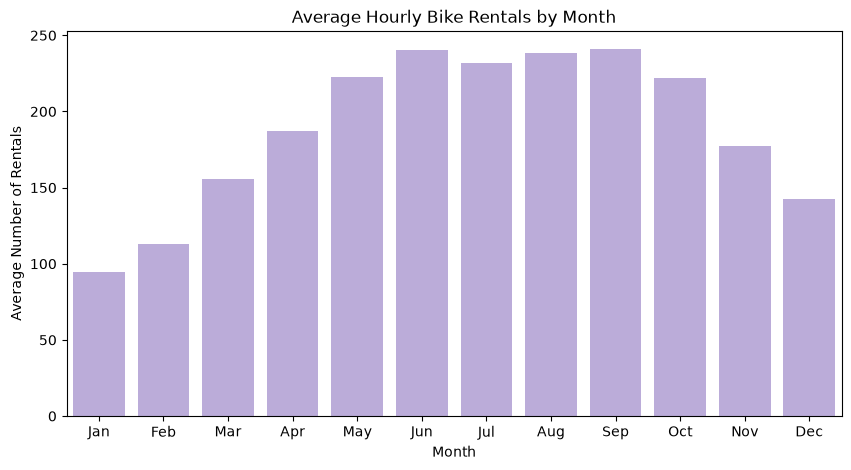

In [48]:
monthly_demand = (
    data
    .groupby('mnth')['cnt']
    .agg(avg_rentals='mean', records='count')
    .reset_index()
)

month_names = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
monthly_demand['month_name'] = monthly_demand['mnth'].map(month_names)

print(monthly_demand)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_demand,
    x='month_name',
    y='avg_rentals',
    color="#B9A5E0"
)


plt.title('Average Hourly Bike Rentals by Month')
plt.xlabel('Month')
plt.ylabel('Average Number of Rentals')

plt.show()


- Average hourly rentals rise from about 94 in January to about 241 in June, stay at roughly 232-241 from June to September, and then decline to about 142 in December.
- The differences among June, July, August and September are small (a few rentals), so no single summer month should be singled out as the highest.
- January has the lowest average, about 2.5 times lower than the summer plateau.
- Each month has a similar number of records (1,341-1,488), so the averages are comparably reliable.
- Both years are combined, and demand was higher in 2012, so the monthly averages partly reflect this difference.

In [49]:
print(pd.crosstab(data['season'], data['mnth']))

mnth      1     2    3     4     5    6     7     8     9     10    11   12
season                                                                     
1       1429  1341  949     0     0    0     0     0     0     0     0  523
2          0     0  524  1437  1488  960     0     0     0     0     0    0
3          0     0    0     0     0  480  1488  1475  1053     0     0    0
4          0     0    0     0     0    0     0     0   384  1451  1437  960


## 14. EDA Summary

### What we learned about demand

- **Target variable.** Hourly rentals (`cnt`) are right-skewed: the mean is about 189 and the median is 142, so most hours have relatively low demand and high values are rarer.
- **Time of day.** Demand has a strong daily pattern, with low demand at night. On working days there are two sharp peaks (around 8:00 and 17:00-18:00), while on weekends and holidays there is a single broad peak around midday. The daily averages of the two day types are similar (about 193 and 181), but their hourly shapes are very different, so the effect of `hr` depends on `workingday`.
- **Season and month.** Demand is highest in summer (about 236) and lowest in winter (about 111). By month, it rises from about 94 in January to about 241 in June, stays at roughly 232-241 until September, and falls to about 142 in December.
- **Year.** Average demand was substantially higher in 2012 (about 235) than in 2011 (about 144). The cause is unknown.
- **Weather.** Demand decreases as `weathersit` worsens across categories 1-3 (about 205, 175 and 112). Category 4 has only 3 records, so no reliable conclusion can be drawn for it.
- **Temperature.** Average demand grows with temperature, from about 40 below -5 °C to about 331 at 30-35 °C, and levels off at roughly 25-35 °C. The correlation with `cnt` is moderate (Pearson 0.405, Spearman 0.423). Humidity has a moderate negative correlation (-0.32) and wind speed a very weak one (0.09).
- **Variability.** At any given temperature, humidity or wind speed, hourly rentals vary widely, so no single weather feature explains demand on its own.
- **Other calendar features.** Differences between weekdays are small (highest on Thursday and Friday, lowest on Sunday). Demand is lower on holidays (about 157) than on regular days (about 190), but the holiday group covers only 21 distinct days.

### Data issues to handle during data preparation

- `casual` and `registered` sum to `cnt` and must not be used as features (target leakage).
- `temp` and `atemp` are almost redundant (correlation 0.99).
- `atemp` is constant (0.2424) for all 24 hours of 2012-08-17, while `temp` changes.
- `hum` equals 0 for 22 records on 2011-03-10, which is not physically plausible.
- `windspeed` equals 0 in 2,180 records (about 12.5%) across 521 dates, with a gap up to the next value (0.0896). Zeros may mean wind below a measurement threshold or missing measurements.
- Some hours are absent from the data (8,645 records in 2011 and 8,734 in 2012, compared with 8,760 and 8,784 hours in those years).
- `weathersit = 4` has only 3 records, and `holiday = 1` covers only 21 days.
- The `season` codes are 1 = winter, 2 = spring, 3 = summer, 4 = fall (confirmed by comparing `season` with `mnth`).

### Implications for the next stage

- Because the data are ordered in time and demand level shifts between years, the way we split data into training, validation and test sets must be chosen carefully to avoid leaking future information into the past.
- The skewed target may motivate testing a log transformation, but the decision will be based on model comparison.
- The interaction between `hr` and `workingday` may matter for models that do not capture interactions on their own.
- The usefulness of each feature (including `atemp`, `weekday`, `holiday` and `windspeed`) will be checked during modeling, not decided from a single plot.
- All findings show association, not causation.